# Student distilled from the SE-WRN-28-10 + SLA teacher (attention in the teacher only)

Final model: one ResNeXt-29 (SLA+SD), 4,998,738 params, no attention. Teachers: SE-WRN-28-10 + SLA (internal test 0.9848), our best student (0.9804), and the ResNet SAM run; section 9b calibrates them and picks their weights on validation. Same recipe as the 98.04 run (400 epochs, cutout 16, ASAM, CutMix, EMA, teachers see the same augmented batch).

Runtime → A100, Run all. If Colab disconnects, Run all again: training resumes from `last.pt`.


Runtime > Change runtime type > A100, then Runtime > Run all. If the session dies, Run all again: training resumes from `runs/<RUN_NAME>/last.pt` (teacher selection is recomputed identically from the saved teachers).

What is new compared with the 0.90 run (`final_resnext29_5M_asam_cosine_slasd_v1`, internal test 97.60):

| Step | What it does | Source |
|---|---|---|
| Teacher calibration | Each teacher gets one temperature T fitted on VALIDATION so its confidence matches its accuracy, before averaging | Guo, Pleiss, Sun, Weinberger, *On Calibration of Modern Neural Networks*, ICML 2017 |
| Teacher selection | Greedy forward selection with replacement on validation log-loss; repeats act as weights, unhelpful teachers get weight 0 | Caruana, Niculescu-Mizil, Crew, Ksikes, *Ensemble Selection from Libraries of Models*, ICML 2004 |
| Gate | Prints the ensemble's INTERNAL TEST accuracy vs the best single teacher and stops before training if it is not better | our rule |
| Distillation | Teachers see exactly the same augmented, CutMixed batch as the student (computed live every step), heavy augmentation, long schedule; KD loss on the 10-class head that is submitted | Beyer et al., *Knowledge distillation: A good teacher is patient and consistent*, CVPR 2022; Hinton et al. 2015 |
| Student | Same SLA+SD ResNeXt-29 recipe as the 0.90 run (ASAM 0.5, cosine, TrivialAugment, CutMix, EMA, label smoothing) | SLA+SD, Lee et al. 2020 |
| Longer + cutout 16 | 400 epochs (the 200-epoch run was still improving at its last epoch); cutout 16 as in the Cutout and TrivialAugment CIFAR-10 setups | DeVries & Taylor 2017; Muller & Hutter 2021 |
| Inference | single network, flip TTA; SD head, AG, or SD+AG average chosen on validation | SLA paper |

Teachers: every finished run on Drive with the same split, minus names matching `TEACHER_EXCLUDE` (cost penalty, Shake-Shake, AugMix). The selection decides the weights. Rules: teachers are our own from-scratch models on the 45k training split, used only during training; no pretrained weights, no external data, no pseudo-labels; the hidden test set is used only for the final submission.

Losses per step: joint class x rotation head = cross-entropy on hard (CutMix-mixed) labels, as in SLA. 10-class head = `KD_ALPHA` x KL(teacher ensemble || student) + (1 - `KD_ALPHA`) x SLA self-distillation.


## 1. Config (every knob lives here)

In [1]:
CFG = dict(
    RUN_NAME="kd_sewrn_only_student_resnext29_slasd_400ep_v1",
    KAGGLE_COMPETITION="cifar-10-res-net-architecture-challenge-dl",
    DRIVE_PROJECT_DIR="cifar10_resnet_challenge",
    LOCAL_DATA_DIR=None,

    # split: identical to every earlier run (45k train / 2.5k val / 2.5k internal test)
    SPLIT_SEED=42, VAL_FRAC=0.05, TEST_FRAC=0.05,

    # model: ResNeXt-29 4x24d, widths 280/528/1040 + SLA joint head -> 4,998,738 trainable parameters
    ARCH="resnext", CARDINALITY=4, BOTTLENECK_WIDTH=24,
    WIDTHS=(280, 528, 1040), BLOCKS=(3, 3, 3),
    DROPOUT=0.0, PARAM_LIMIT=5_000_000,

    # optimiser and schedule (same as the 98.04 run, new seed)
    SEED=16, EPOCHS=400, BATCH_SIZE=256,
    MAX_LR=0.2, MOMENTUM=0.9, WEIGHT_DECAY=5e-4, LABEL_SMOOTHING=0.1,
    LR_SCHEDULE="cosine", WARMUP_EPOCHS=5,
    PCT_WARMUP=0.25,
    EARLY_STOP_PATIENCE=None, MAX_EPOCHS_THIS_SESSION=None,

    # sharpness-aware training: ASAM
    SAM_RHO=0.5, SAM_ADAPTIVE=True,

    # SLA+SD
    SLA=True, SLA_ROTATIONS=4, SLA_SD_WEIGHT=1.0,

    # weight averaging
    EMA_DECAY=0.999,

    # augmentation
    AUGMENT=True, CUTOUT=16, TRIVIAL_AUG=True, TA_GROUP=16, GRAYSCALE_P=0.1, TTA_FLIP=True,
    MIX_PROB=0.5, MIXUP_SHARE=0.0, MIXUP_ALPHA=0.4, CUTMIX_P=0.5, CUTMIX_ALPHA=1.0,

    # distillation from ONE teacher: SE-WRN-28-10 + SLA (internal test 0.9848, attention in the teacher only)
    KD_ALPHA=0.9,
    KD_T=1.0,
    TEACHER_RUNS=["teacher_sewrn28_10_sla250_v1"],
    ENSEMBLE_WEIGHTS="equal",
    TEACHER_EXCLUDE=("costpen", "shake", "augmix"),
    KD_MIN_TEACHER_VAL=0.955,
    CALIBRATE_TEACHERS=True, ENSEMBLE_ROUNDS=25, KD_REQUIRE_GAIN=False,

    # options kept available but OFF in this recipe
    AUGMIX=False, AUGMIX_WIDTH=3, AUGMIX_ALPHA=1.0, AUGMIX_GROUP=32, JSD_LAMBDA=12.0,
    COST_LAMBDA=0.0, COST_MIN_COUNT=3, COST_REF_RUN=None,

    USE_BF16=True,
)
print("RUN_NAME:", CFG["RUN_NAME"])
CFG

RUN_NAME: kd_sewrn_only_student_resnext29_slasd_400ep_v1


{'RUN_NAME': 'kd_sewrn_only_student_resnext29_slasd_400ep_v1',
 'KAGGLE_COMPETITION': 'cifar-10-res-net-architecture-challenge-dl',
 'DRIVE_PROJECT_DIR': 'cifar10_resnet_challenge',
 'LOCAL_DATA_DIR': None,
 'SPLIT_SEED': 42,
 'VAL_FRAC': 0.05,
 'TEST_FRAC': 0.05,
 'ARCH': 'resnext',
 'CARDINALITY': 4,
 'BOTTLENECK_WIDTH': 24,
 'WIDTHS': (280, 528, 1040),
 'BLOCKS': (3, 3, 3),
 'DROPOUT': 0.0,
 'PARAM_LIMIT': 5000000,
 'SEED': 16,
 'EPOCHS': 400,
 'BATCH_SIZE': 256,
 'MAX_LR': 0.2,
 'MOMENTUM': 0.9,
 'WEIGHT_DECAY': 0.0005,
 'LABEL_SMOOTHING': 0.1,
 'LR_SCHEDULE': 'cosine',
 'WARMUP_EPOCHS': 5,
 'PCT_WARMUP': 0.25,
 'EARLY_STOP_PATIENCE': None,
 'MAX_EPOCHS_THIS_SESSION': None,
 'SAM_RHO': 0.5,
 'SAM_ADAPTIVE': True,
 'SLA': True,
 'SLA_ROTATIONS': 4,
 'SLA_SD_WEIGHT': 1.0,
 'EMA_DECAY': 0.999,
 'AUGMENT': True,
 'CUTOUT': 16,
 'TRIVIAL_AUG': True,
 'TA_GROUP': 16,
 'GRAYSCALE_P': 0.1,
 'TTA_FLIP': True,
 'MIX_PROB': 0.5,
 'MIXUP_SHARE': 0.0,
 'MIXUP_ALPHA': 0.4,
 'CUTMIX_P': 0.5,
 'CU

## 2. Environment, Drive, GPU

In [2]:
import os, sys, json, time, math, random, re, shutil, tarfile, zipfile, glob
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = os.path.join("/content/drive/MyDrive", CFG["DRIVE_PROJECT_DIR"])
    WORK_DIR = "/content/work"
else:
    DRIVE_ROOT = os.path.abspath(os.path.join(os.environ.get("DRIVE_ROOT_OVERRIDE", "./drive_sim"), CFG["DRIVE_PROJECT_DIR"]))
    WORK_DIR = os.path.abspath(os.environ.get("WORK_DIR_OVERRIDE", "./work"))

DATA_DIR  = os.path.join(DRIVE_ROOT, "data")
CACHE_DIR = os.path.join(DATA_DIR, "cache")
SPLIT_DIR = os.path.join(DATA_DIR, "splits")
RUN_DIR   = os.path.join(DRIVE_ROOT, "runs", CFG["RUN_NAME"])
for d in (CACHE_DIR, SPLIT_DIR, RUN_DIR, WORK_DIR):
    os.makedirs(d, exist_ok=True)
print("Drive project dir:", DRIVE_ROOT)
print("Run dir:", RUN_DIR)

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu = torch.cuda.get_device_name(0)
    print("GPU:", gpu)
    if "A100" not in gpu:
        print("WARNING: not an A100. Code still runs; bf16 needs Ampere or newer.")
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    device = torch.device("cpu")
    print("WARNING: no GPU found. In Colab: Runtime > Change runtime type > A100 GPU.")
print("torch", torch.__version__)

AMP_DTYPE = torch.bfloat16 if CFG["USE_BF16"] and (device.type == "cpu" or torch.cuda.is_bf16_supported()) else None

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["SEED"])

def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

Mounted at /content/drive
Drive project dir: /content/drive/MyDrive/cifar10_resnet_challenge
Run dir: /content/drive/MyDrive/cifar10_resnet_challenge/runs/kd_sewrn_only_student_resnext29_slasd_400ep_v1
GPU: NVIDIA A100-SXM4-80GB
torch 2.11.0+cu130


## 3. Get the competition data from Drive (skipped when the decoded cache already exists)

In [3]:
# ---- 3. Load competition data from Google Drive (no Kaggle) ----
MANIFEST = os.path.join(CACHE_DIR, "manifest.json")
RAW_DIR = os.path.join(WORK_DIR, "raw")      # local Colab disk (fast)

def extract_zip(zpath, dest_root):
    stem = os.path.splitext(os.path.basename(zpath))[0]
    t0 = time.time()
    with zipfile.ZipFile(zpath) as z:
        members = [m for m in z.namelist()
                   if not m.startswith("__MACOSX") and not os.path.basename(m).startswith("._") and not m.endswith(".DS_Store")]
        has_top = all(m.startswith(stem + "/") for m in members)
        dest = dest_root if has_top else os.path.join(dest_root, stem)
        for m in members:
            z.extract(m, dest)
    print(f"extracted {os.path.basename(zpath)} ({len(members)} entries) in {time.time()-t0:.0f}s")

def copy_folder(src, dst):
    os.makedirs(dst, exist_ok=True)
    files = [f for f in os.listdir(src) if not f.startswith(".")]
    t0 = time.time()
    for i, f in enumerate(files, 1):
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))
        if i % 500 == 0 or i == len(files):
            print(f"  copied {i}/{len(files)} files ({time.time()-t0:.0f}s)")

def get_data_from_drive():
    os.makedirs(RAW_DIR, exist_ok=True)
    for name in ["train_images", "test_images"]:
        local = os.path.join(RAW_DIR, name)
        if os.path.isdir(local) and os.listdir(local):
            print(name, "already on local disk"); continue
        zp, fp = os.path.join(DATA_DIR, name + ".zip"), os.path.join(DATA_DIR, name)
        if os.path.exists(zp):
            extract_zip(zp, RAW_DIR)
        elif os.path.isdir(fp):
            print(f"copying {name} folder from Drive ...")
            copy_folder(fp, local)
        else:
            raise FileNotFoundError(f"Neither {zp} nor folder {fp} found")
    for f in ["train_labels.csv", "test.csv", "sample_submission.csv"]:
        src = os.path.join(DATA_DIR, f)
        assert os.path.exists(src), f"Missing {src}"
        shutil.copy(src, os.path.join(RAW_DIR, f))
    return RAW_DIR

NEED_BUILD = not os.path.exists(MANIFEST)
if NEED_BUILD:
    SRC_DIR = CFG["LOCAL_DATA_DIR"] or get_data_from_drive()
    print("\nCompetition files:")
    for root, dirs, files in os.walk(SRC_DIR):
        if root[len(SRC_DIR):].count(os.sep) <= 2:
            print(" ", root, "|", len(files), "files", sorted(files)[:3])
else:
    print("Decoded cache found on Drive, skipping raw files:", MANIFEST)

Decoded cache found on Drive, skipping raw files: /content/drive/MyDrive/cifar10_resnet_challenge/data/cache/manifest.json


## 4. Build the decoded cache (first session only)

Each CSV is matched to the image files by trying every column as an exact file name, file stem, or numeric id, and only a 100% one-to-one match is accepted. Labels may be integers 0 to 9 or class names. The test ids are aligned to `sample_submission.csv`. Every decision is printed so you can confirm it.

In [4]:
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")

def find_path(root, name, want_dir):
    hits = []
    for r, ds, fs in os.walk(root):
        pool = ds if want_dir else fs
        if name in pool:
            hits.append(os.path.join(r, name))
    hits.sort(key=lambda p: p.count(os.sep))
    return hits[0] if hits else None

def list_images(d):
    out = [os.path.join(r, f) for r, _, fs in os.walk(d) for f in fs if f.lower().endswith(IMG_EXT)]
    return sorted(out)

def file_index(files):
    base = {os.path.basename(f): f for f in files}
    stem = {os.path.splitext(os.path.basename(f))[0]: f for f in files}
    num = {}
    for f in files:
        m = re.findall(r"\d+", os.path.splitext(os.path.basename(f))[0])
        if m: num.setdefault(int(m[-1]), []).append(f)
    num = {k: v[0] for k, v in num.items() if len(v) == 1} if all(len(v) == 1 for v in num.values()) and len(num) == len(files) else None
    assert len(base) == len(files), "Duplicate image file names in different subfolders."
    return {"basename": base, "stem": stem, "numeric": num}

def map_column(series, idx, strategy):
    if strategy == "numeric":
        if idx["numeric"] is None: return None
        v = pd.to_numeric(series, errors="coerce")
        if v.isna().any() or (v % 1 != 0).any(): return None
        return v.astype(int).map(idx["numeric"])
    s = series.astype(str).str.strip()
    if strategy == "basename": s = s.map(os.path.basename)
    return s.map(idx[strategy])

def resolve_key(df, files, name):
    idx = file_index(files)
    rows = []
    for strategy in ("basename", "stem", "numeric"):
        for col in df.columns:
            m = map_column(df[col], idx, strategy)
            frac = 0.0 if m is None else m.notna().mean()
            uniq = m is not None and m.notna().all() and m.nunique() == len(df)
            rows.append((col, strategy, round(float(frac), 4), uniq))
    print(f"[{name}] key candidates (column, strategy, match fraction, one-to-one):")
    for r in rows:
        if r[2] > 0: print("   ", r)
    ok = [r for r in rows if r[2] == 1.0 and r[3]]
    if not ok:
        raise RuntimeError(f"[{name}] no column maps 1:1 onto the {len(files)} image files. CSV head:\n{df.head()}\n"
                           f"file examples: {[os.path.basename(f) for f in files[:5]]}")
    col, strategy = ok[0][0], ok[0][1]
    print(f"[{name}] using column '{col}' as {strategy} key")
    return col, map_column(df[col], idx, strategy).values

def resolve_labels(df, key_col):
    cands = {}
    for col in df.columns:
        if col == key_col: continue
        s = df[col]
        v = pd.to_numeric(s, errors="coerce")
        if v.notna().all() and (v % 1 == 0).all() and set(v.astype(int).unique()) <= set(range(10)) and v.nunique() == 10:
            cands[col] = v.astype(int).values
        elif v.isna().all():   # text column (works for object and pandas string dtypes)
            low = s.astype(str).str.strip().str.lower()
            if set(low.unique()) <= set(CLASS_NAMES) and low.nunique() == 10:
                cands[col] = low.map({c: i for i, c in enumerate(CLASS_NAMES)}).values
    if not cands:
        raise RuntimeError(f"No label column found. Columns: {list(df.columns)}\n{df.head()}")
    cols = list(cands)
    for c in cols[1:]:
        assert (cands[c] == cands[cols[0]]).all(), f"Label columns {cols[0]} and {c} disagree."
    print(f"[train] label column(s): {cols} -> using '{cols[0]}'")
    return cands[cols[0]]

def decode(paths):
    def one(p):
        a = np.array(Image.open(p).convert("RGB"))
        assert a.shape == (32, 32, 3), f"{p} has shape {a.shape}"
        return a
    with ThreadPoolExecutor(16) as ex:
        return np.stack(list(ex.map(one, paths)))

if NEED_BUILD:
    tr_csv = find_path(SRC_DIR, "train_labels.csv", False)
    te_csv = find_path(SRC_DIR, "test.csv", False)
    ss_csv = find_path(SRC_DIR, "sample_submission.csv", False)
    tr_dir = find_path(SRC_DIR, "train_images", True)
    te_dir = find_path(SRC_DIR, "test_images", True)
    print("train csv:", tr_csv, "\ntest csv:", te_csv, "\nsample sub:", ss_csv, "\ntrain dir:", tr_dir, "\ntest dir:", te_dir)
    assert tr_csv and ss_csv and tr_dir and te_dir, "Expected files not found, see listing above."

    # ---------- train ----------
    tr_df = pd.read_csv(tr_csv)
    print("\ntrain_labels.csv", tr_df.shape, "\n", tr_df.head())
    tr_files = list_images(tr_dir)
    print("train images:", len(tr_files))
    assert len(tr_df) == len(tr_files), f"{len(tr_df)} label rows vs {len(tr_files)} images"
    key_col, tr_paths = resolve_key(tr_df, tr_files, "train")
    y_full = resolve_labels(tr_df, key_col).astype(np.int64)

    # ---------- test ----------
    ss = pd.read_csv(ss_csv)
    print("\nsample_submission", ss.shape, "\n", ss.head(3))
    assert list(ss.columns) == ["id", "label"], ss.columns
    te_files = list_images(te_dir)
    print("test images:", len(te_files))
    assert len(te_files) == len(ss), f"{len(te_files)} test images vs {len(ss)} submission rows"
    sub_ids = set(ss["id"].tolist())
    te_df = pd.read_csv(te_csv) if te_csv else None
    id_cols = []
    if te_df is not None:
        print("\ntest.csv", te_df.shape, "\n", te_df.head())
        tkey, te_paths = resolve_key(te_df, te_files, "test")
        for c in te_df.columns:
            v = pd.to_numeric(te_df[c], errors="coerce")
            if v.notna().all() and (v % 1 == 0).all() and set(v.astype(int).tolist()) == sub_ids:
                id_cols.append(c)
    if id_cols:
        id_col = "id" if "id" in id_cols else id_cols[0]
        print(f"[test] id column in test.csv: '{id_col}'")
        te_ids = pd.to_numeric(te_df[id_col]).astype(int).values
    else:
        print("[test] test.csv missing or has no id column matching sample_submission, trying file numbers")
        idx = file_index(te_files)
        assert idx["numeric"] is not None and set(idx["numeric"]) == sub_ids, "No test.csv and file numbers do not match ids."
        te_ids = np.array(sorted(sub_ids)); te_paths = np.array([idx["numeric"][i] for i in te_ids])
        print("[test] ids taken from file numbers")
    order = pd.Series(range(len(te_ids)), index=te_ids).loc[ss["id"].values].values   # sample_submission order
    te_ids, te_paths = te_ids[order], np.asarray(te_paths)[order]
    print("[test] first mappings:", list(zip(te_ids[:5].tolist(), [os.path.basename(p) for p in te_paths[:5]])))

    print("\nDecoding images ...")
    t0 = time.time()
    X_full = decode(tr_paths); X_test = decode(te_paths)
    print(f"decoded in {time.time()-t0:.0f}s", X_full.shape, X_test.shape)

    np.save(os.path.join(CACHE_DIR, "train_x.npy"), X_full)
    np.save(os.path.join(CACHE_DIR, "train_y.npy"), y_full)
    np.save(os.path.join(CACHE_DIR, "train_files.npy"), np.array([os.path.basename(p) for p in tr_paths]))
    np.save(os.path.join(CACHE_DIR, "test_x.npy"), X_test)
    np.save(os.path.join(CACHE_DIR, "test_ids.npy"), te_ids)
    np.save(os.path.join(CACHE_DIR, "test_files.npy"), np.array([os.path.basename(p) for p in te_paths]))
    ss.to_csv(os.path.join(CACHE_DIR, "sample_submission.csv"), index=False)
    with open(MANIFEST, "w") as f:   # written last: its presence means the cache is complete
        json.dump({"n_train": int(len(X_full)), "n_test": int(len(X_test)), "train_key_col": key_col,
                   "created": time.strftime("%Y-%m-%d %H:%M:%S")}, f, indent=1)
    print("Cache saved to Drive:", CACHE_DIR)

## 5. Load cache and sanity-check it

manifest: {'n_train': 50000, 'n_test': 2000, 'train_key_col': 'filename', 'created': '2026-10-30 04:09:47'}
train: (50000, 32, 32, 3) uint8 | test: (2000, 32, 32, 3)
class counts: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


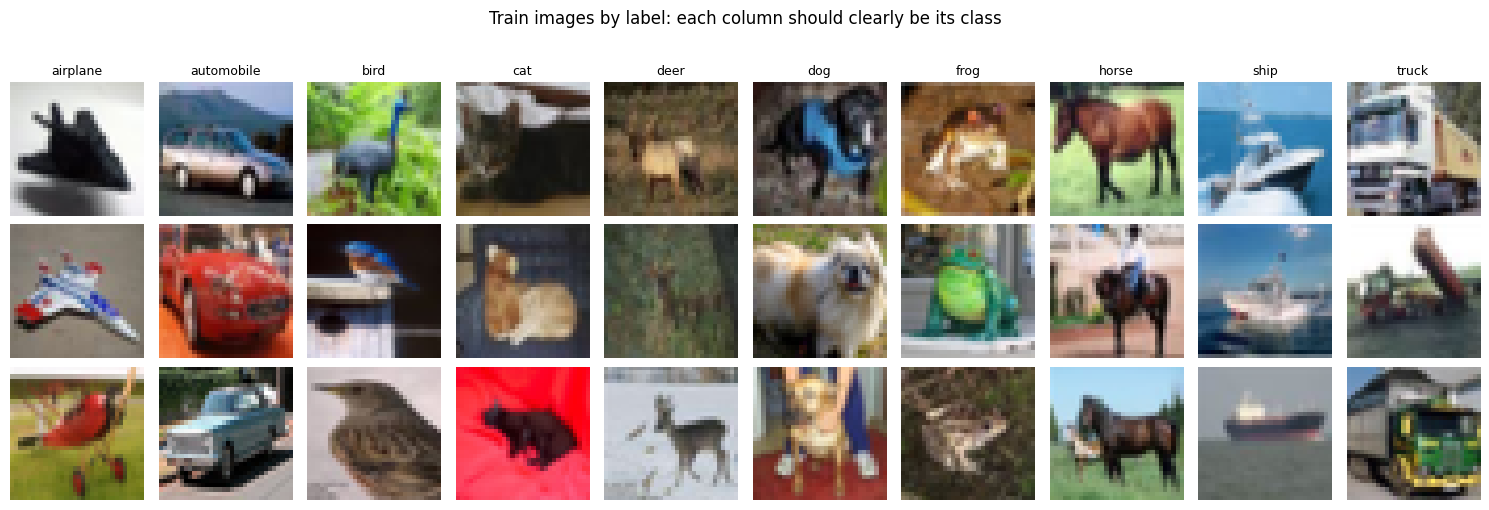

In [5]:
X_full = np.load(os.path.join(CACHE_DIR, "train_x.npy"))
y_full = np.load(os.path.join(CACHE_DIR, "train_y.npy"))
X_test = np.load(os.path.join(CACHE_DIR, "test_x.npy"))
test_ids = np.load(os.path.join(CACHE_DIR, "test_ids.npy"))
SAMPLE_SUB = pd.read_csv(os.path.join(CACHE_DIR, "sample_submission.csv"))
print("manifest:", json.load(open(MANIFEST)))
print("train:", X_full.shape, X_full.dtype, "| test:", X_test.shape)
assert X_full.dtype == np.uint8 and X_full.shape[1:] == (32, 32, 3)
assert len(X_full) == len(y_full) and (test_ids == SAMPLE_SUB["id"].values).all()
counts = np.bincount(y_full, minlength=10)
print("class counts:", dict(zip(CLASS_NAMES, counts.tolist())))

fig, axs = plt.subplots(3, 10, figsize=(15, 5))
for c in range(10):
    for r, i in enumerate(np.where(y_full == c)[0][:3]):
        axs[r, c].imshow(X_full[i]); axs[r, c].axis("off")
    axs[0, c].set_title(CLASS_NAMES[c], fontsize=9)
plt.suptitle("Train images by label: each column should clearly be its class", y=1.02); plt.tight_layout(); plt.show()

## 6. Stratified train / val / test split

`train_test_split(..., stratify=y)` twice, so all three parts have the same class proportions (250 per class in val and in test when the data is balanced). The internal test part is only scored once at the end, so it gives an honest estimate of leaderboard accuracy. The split is saved to Drive and reused by every run and every resume.

In [6]:
from sklearn.model_selection import train_test_split
split_path = os.path.join(SPLIT_DIR, f"split_seed{CFG['SPLIT_SEED']}_val{CFG['VAL_FRAC']}_test{CFG['TEST_FRAC']}_n{len(y_full)}.npz")
if os.path.exists(split_path):
    s = np.load(split_path); tr_idx, va_idx, te_idx = s["train"], s["val"], s["test"]
    print("Loaded split from Drive:", split_path)
else:
    all_idx = np.arange(len(y_full))
    trva_idx, te_idx = train_test_split(all_idx, test_size=CFG["TEST_FRAC"], stratify=y_full, random_state=CFG["SPLIT_SEED"])
    tr_idx, va_idx = train_test_split(trva_idx, test_size=CFG["VAL_FRAC"] / (1 - CFG["TEST_FRAC"]),
                                      stratify=y_full[trva_idx], random_state=CFG["SPLIT_SEED"])
    np.savez(split_path, train=tr_idx, val=va_idx, test=te_idx)
    print("Saved split to Drive:", split_path)
assert len(set(tr_idx) & set(va_idx)) == 0 and len(set(tr_idx) & set(te_idx)) == 0 and len(set(va_idx) & set(te_idx)) == 0
assert len(tr_idx) + len(va_idx) + len(te_idx) == len(y_full)
tab = pd.DataFrame({n: np.bincount(y_full[i], minlength=10) for n, i in [("train", tr_idx), ("val", va_idx), ("test", te_idx)]},
                   index=CLASS_NAMES)
tab.loc["TOTAL"] = tab.sum()
print(tab)

Loaded split from Drive: /content/drive/MyDrive/cifar10_resnet_challenge/data/splits/split_seed42_val0.05_test0.05_n50000.npz
            train   val  test
airplane     4500   250   250
automobile   4500   250   250
bird         4500   250   250
cat          4500   250   250
deer         4500   250   250
dog          4500   250   250
frog         4500   250   250
horse        4500   250   250
ship         4500   250   250
truck        4500   250   250
TOTAL       45000  2500  2500


## 7. GPU tensors, normalisation, optional augmentation

mean [0.4912, 0.4821, 0.4464] std [0.2469, 0.2434, 0.2616]
augmentation: ON | TrivialAugment: True | grayscale p: 0.1 | train (45000, 3, 32, 32) val (2500, 3, 32, 32) internal test (2500, 3, 32, 32) kaggle test (2000, 3, 32, 32)


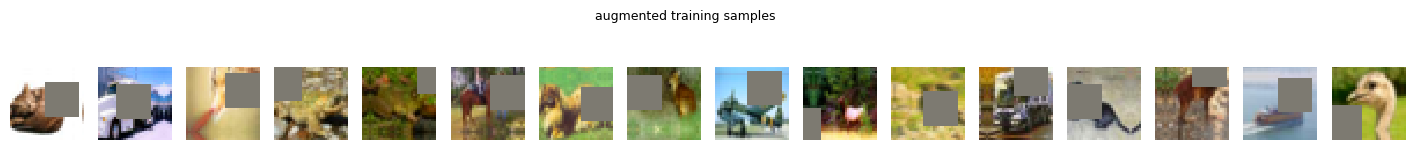

In [7]:
from torchvision.transforms import v2 as T

def to_dev(x): return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(device)   # N,3,32,32 uint8
Xtr, ytr = to_dev(X_full[tr_idx]), torch.from_numpy(y_full[tr_idx]).to(device)
Xva, yva = to_dev(X_full[va_idx]), torch.from_numpy(y_full[va_idx]).to(device)
Xte_int, yte_int = to_dev(X_full[te_idx]), torch.from_numpy(y_full[te_idx]).to(device)
Xkaggle = to_dev(X_test)

# statistics from the training part only (no leakage from val/test)
_f = Xtr.float() / 255
MEAN = _f.mean(dim=(0, 2, 3)).view(1, 3, 1, 1); STD = _f.std(dim=(0, 2, 3)).view(1, 3, 1, 1); del _f
print("mean", [round(v, 4) for v in MEAN.flatten().tolist()], "std", [round(v, 4) for v in STD.flatten().tolist()])

def normalize(x_u8):
    x = (x_u8.float() / 255 - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

_trivial = T.TrivialAugmentWide()

def photometric(x_u8):
    """TrivialAugment (one random op per small group of images) + random grayscale, on uint8 GPU tensors."""
    if CFG.get("TRIVIAL_AUG", False):
        g = CFG.get("TA_GROUP", 8)
        x_u8 = torch.cat([_trivial(c) for c in x_u8.split(g)])      # each chunk of g images gets its own random op
    p = CFG.get("GRAYSCALE_P", 0.0)
    if p > 0:
        gray = (x_u8.float() * torch.tensor([0.299, 0.587, 0.114], device=x_u8.device).view(1, 3, 1, 1)).sum(1, keepdim=True)
        gray = gray.round().clamp(0, 255).to(torch.uint8).expand(-1, 3, -1, -1)
        m = (torch.rand(len(x_u8), device=x_u8.device) < p)[:, None, None, None]
        x_u8 = torch.where(m, gray, x_u8)
    return x_u8

def augment(x_u8):
    x_u8 = photometric(x_u8)
    x = (x_u8.float() / 255 - MEAN) / STD
    n, dev = x.size(0), x.device
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    dy = torch.randint(0, 9, (n,), device=dev); dx = torch.randint(0, 9, (n,), device=dev)
    ar = torch.arange(32, device=dev)
    x = xp[torch.arange(n, device=dev)[:, None, None, None], torch.arange(3, device=dev)[None, :, None, None],
           (dy[:, None] + ar)[:, None, :, None], (dx[:, None] + ar)[:, None, None, :]]
    flip = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    if CFG["CUTOUT"] > 0:
        cy = torch.randint(0, 32, (n,), device=dev); cx = torch.randint(0, 32, (n,), device=dev); h = CFG["CUTOUT"] // 2
        m = ((ar[None, :, None] - cy[:, None, None]).abs() < h) & ((ar[None, None, :] - cx[:, None, None]).abs() < h)
        x = x * (~m)[:, None].float()
    return x.contiguous(memory_format=torch.channels_last)

prep_train = augment if CFG["AUGMENT"] else normalize
print("augmentation:", "ON" if CFG["AUGMENT"] else "OFF",
      "| TrivialAugment:", CFG.get("TRIVIAL_AUG", False), "| grayscale p:", CFG.get("GRAYSCALE_P", 0.0),
      "| train", tuple(Xtr.shape), "val", tuple(Xva.shape), "internal test", tuple(Xte_int.shape), "kaggle test", tuple(Xkaggle.shape))

# preview: 16 training images after augmentation (un-normalised for display)
if CFG["AUGMENT"]:
    _s = augment(Xtr[:16]).float() * STD + MEAN
    fig, axs = plt.subplots(1, 16, figsize=(18, 1.6))
    for a, im in zip(axs, _s.clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()):
        a.imshow(im, interpolation="nearest"); a.axis("off")
    plt.suptitle("augmented training samples", y=1.08, fontsize=9); plt.show()
import torchvision.transforms.v2.functional as TF

# ---- AugMix (Hendrycks et al., ICLR 2020): several random augmentation chains mixed together, used with a JSD consistency loss ----
# Ops follow the paper's list (it deliberately leaves out blur/noise/contrast-style ops). Severity about 3, as in the paper.
AUGMIX_OPS = ["autocontrast", "equalize", "posterize", "rotate", "solarize", "shear_x", "shear_y", "translate_x", "translate_y"]

def _augmix_op(x, op):
    r = np.random
    if op == "autocontrast": return TF.autocontrast(x)
    if op == "equalize":     return TF.equalize(x)
    if op == "posterize":    return TF.posterize(x, int(r.choice([2, 3, 4])))
    if op == "solarize":     return TF.solarize(x, float(r.uniform(180, 255)))
    if op == "rotate":       return TF.rotate(x, float(r.uniform(-9, 9)))
    if op == "shear_x":      return TF.affine(x, angle=0.0, translate=[0, 0], scale=1.0, shear=[float(r.uniform(-5, 5)), 0.0])
    if op == "shear_y":      return TF.affine(x, angle=0.0, translate=[0, 0], scale=1.0, shear=[0.0, float(r.uniform(-5, 5))])
    if op == "translate_x":  return TF.affine(x, angle=0.0, translate=[int(r.randint(-3, 4)), 0], scale=1.0, shear=[0.0, 0.0])
    if op == "translate_y":  return TF.affine(x, angle=0.0, translate=[0, int(r.randint(-3, 4))], scale=1.0, shear=[0.0, 0.0])
    raise ValueError(op)

def spatial_u8(x_u8):
    """Random crop (pad 4, reflect) + horizontal flip, staying in uint8."""
    x = F.pad(x_u8.float(), (4, 4, 4, 4), mode="reflect")
    n, dev = x.size(0), x.device
    dy = torch.randint(0, 9, (n,), device=dev); dx = torch.randint(0, 9, (n,), device=dev)
    ar = torch.arange(32, device=dev)
    x = x[torch.arange(n, device=dev)[:, None, None, None], torch.arange(3, device=dev)[None, :, None, None],
          (dy[:, None] + ar)[:, None, :, None], (dx[:, None] + ar)[:, None, None, :]]
    flip = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    return x.round().clamp(0, 255).to(torch.uint8)

def augmix(x_u8, width=3, alpha=1.0, group=32):
    """Returns a float tensor in 0..255: m * original + (1 - m) * sum_k w_k * chain_k(original).
    Each chain has 1-3 random ops; ops are drawn per group of images to keep it fast on the GPU."""
    n, dev = x_u8.size(0), x_u8.device
    w = torch.distributions.Dirichlet(torch.full((width,), float(alpha), device=dev)).sample((n,))
    m = torch.distributions.Beta(torch.tensor(float(alpha), device=dev), torch.tensor(float(alpha), device=dev)).sample((n,))
    mix = torch.zeros(x_u8.shape, device=dev, dtype=torch.float32)
    for k in range(width):
        parts = []
        for g in x_u8.split(group):
            y = g
            for _ in range(np.random.randint(1, 4)):
                y = _augmix_op(y, AUGMIX_OPS[np.random.randint(len(AUGMIX_OPS))])
            parts.append(y)
        mix += w[:, k].view(-1, 1, 1, 1) * torch.cat(parts).float()
    mv = m.view(-1, 1, 1, 1)
    return mv * x_u8.float() + (1 - mv) * mix

def _norm_float255(x):
    return ((x / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def augmix_views(x_u8):
    """Clean view + two independent AugMix views of the same cropped/flipped images."""
    base = spatial_u8(x_u8)
    w, a, g = CFG.get("AUGMIX_WIDTH", 3), CFG.get("AUGMIX_ALPHA", 1.0), CFG.get("AUGMIX_GROUP", 32)
    return _norm_float255(base.float()), _norm_float255(augmix(base, w, a, g)), _norm_float255(augmix(base, w, a, g))

if CFG.get("AUGMIX", False):
    _c, _a1, _a2 = augmix_views(Xtr[:8])
    fig, axs = plt.subplots(3, 8, figsize=(14, 5.4))
    for row, v, name in zip(axs, (_c, _a1, _a2), ("clean", "AugMix view 1", "AugMix view 2")):
        for a, im in zip(row, (v.float() * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()):
            a.imshow(im, interpolation="nearest"); a.axis("off")
        row[0].set_title(name, fontsize=9, loc="left")
    plt.tight_layout(); plt.show()
    print("AugMix ON: width", CFG.get("AUGMIX_WIDTH", 3), "| alpha", CFG.get("AUGMIX_ALPHA", 1.0), "| JSD lambda", CFG.get("JSD_LAMBDA", 12.0))


## 8. Model

CIFAR-style ResNet: 3x3 stem, three stages of BasicBlocks (64, 128, 256 channels, 3 blocks each), identity skips, 1x1 conv + BN projection skips where shape changes, global average pool, linear head. Downsampling happens only twice, so the last stage still works on 8x8 maps, which suits 32x32 inputs better than ImageNet ResNets. Zero-init of the last BN in each block makes every block start as an identity, which stabilises early training.

In [8]:
# ---- 8. Models: ResNet, ResNeXt-29, Shake-Shake, chosen with CFG["ARCH"] ----
class BasicBlock(nn.Module):
    """Post-activation basic block (our original ResNet)."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)

class CifarResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256), blocks=(3, 3, 3), num_classes=10, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, cin = [], widths[0]
        for i, (w, nb) in enumerate(zip(widths, blocks)):
            for j in range(nb):
                layers.append(BasicBlock(cin, w, 2 if (j == 0 and i > 0) else 1)); cin = w
        self.layers = nn.Sequential(*layers)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for b in self.layers: nn.init.zeros_(b.bn2.weight)
    def forward(self, x):
        return self.fc(self.drop(self.features(x)))
    def features(self, x):
        return torch.flatten(F.adaptive_avg_pool2d(self.layers(self.stem(x)), 1), 1)

class ResNeXtBlock(nn.Module):
    """ResNeXt bottleneck: 1x1 conv -> grouped 3x3 conv (cardinality groups) -> 1x1 conv, plus skip (Xie et al. 2017)."""
    def __init__(self, cin, inner, cout, stride, cardinality):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, inner, 1, bias=False); self.bn1 = nn.BatchNorm2d(inner)
        self.conv2 = nn.Conv2d(inner, inner, 3, stride, 1, groups=cardinality, bias=False); self.bn2 = nn.BatchNorm2d(inner)
        self.conv3 = nn.Conv2d(inner, cout, 1, bias=False); self.bn3 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))
        return F.relu(out + self.shortcut(x), inplace=True)

class ResNeXt29(nn.Module):
    """CIFAR ResNeXt-29: 3x3 stem (64) + 3 stages x 3 blocks; output widths 256/512/1024;
    inner width = cardinality * bottleneck_width, doubled at each stage. (2, 64) is the standard 2x64d."""
    def __init__(self, cardinality=2, bottleneck_width=64, blocks=(3, 3, 3), out_widths=(256, 512, 1024),
                 num_classes=10, dropout=0.0, stem=64):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stem, 3, 1, 1, bias=False), nn.BatchNorm2d(stem), nn.ReLU(inplace=True))
        layers, cin = [], stem
        for i, (cout, nb) in enumerate(zip(out_widths, blocks)):
            inner = cardinality * bottleneck_width * (2 ** i)
            for j in range(nb):
                layers.append(ResNeXtBlock(cin, inner, cout, 2 if (j == 0 and i > 0) else 1, cardinality)); cin = cout
        self.layers = nn.Sequential(*layers)
        self.drop = nn.Dropout(dropout); self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for b in self.layers: nn.init.zeros_(b.bn3.weight)
    def forward(self, x):
        return self.fc(self.drop(self.features(x)))
    def features(self, x):
        return torch.flatten(F.adaptive_avg_pool2d(self.layers(self.stem(x)), 1), 1)

class ShakeFn(torch.autograd.Function):
    """Shake-Shake (Gastaldi 2017): forward mixes the two branches with alpha, backward with an independent beta."""
    @staticmethod
    def forward(ctx, x1, x2, alpha, beta):
        ctx.save_for_backward(beta)
        return alpha * x1 + (1 - alpha) * x2
    @staticmethod
    def backward(ctx, g):
        beta, = ctx.saved_tensors
        return beta * g, (1 - beta) * g, None, None

class ShakeBranch(nn.Sequential):
    def __init__(self, cin, cout, stride):
        super().__init__(nn.ReLU(inplace=False), nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout),
                         nn.ReLU(inplace=True), nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout))

class ShakeBlock(nn.Module):
    """Residual block with two parallel branches mixed by random per-image weights during training (0.5/0.5 at test)."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.b1, self.b2 = ShakeBranch(cin, cout, stride), ShakeBranch(cin, cout, stride)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:   # ResNet-D style: average-pool then 1x1 conv, keeps all pixels
            self.shortcut = nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(),
                                          nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        h1, h2 = self.b1(x), self.b2(x)
        if self.training:
            n = x.size(0)
            alpha = torch.rand(n, 1, 1, 1, device=x.device, dtype=h1.dtype)
            beta = torch.rand(n, 1, 1, 1, device=x.device, dtype=h1.dtype)
            h = ShakeFn.apply(h1, h2, alpha, beta)
        else:
            h = 0.5 * (h1 + h2)
        return self.shortcut(x) + h

class ShakeShakeNet(nn.Module):
    """CIFAR Shake-Shake ResNet: 16-ch stem, 3 stages of shake blocks; depth = 6 * blocks_per_stage + 2.
    widths=(32,64,128) with 4 blocks/stage is the published 'Shake-Shake 26 2x32d'."""
    def __init__(self, widths=(32, 64, 128), blocks=(4, 4, 4), num_classes=10, dropout=0.0, stem=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stem, 3, 1, 1, bias=False), nn.BatchNorm2d(stem))
        layers, cin = [], stem
        for i, (w, nb) in enumerate(zip(widths, blocks)):
            for j in range(nb):
                layers.append(ShakeBlock(cin, w, 2 if (j == 0 and i > 0) else 1)); cin = w
        self.layers = nn.Sequential(*layers)
        self.drop = nn.Dropout(dropout); self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        return self.fc(self.drop(self.features(x)))
    def features(self, x):
        return torch.flatten(F.adaptive_avg_pool2d(F.relu(self.layers(self.stem(x))), 1), 1)

class SE(nn.Module):
    """Squeeze-excitation (Hu et al. 2018): channel weights from global average pooling. Teachers only."""
    def __init__(self, c, r=16):
        super().__init__()
        self.fc1, self.fc2 = nn.Conv2d(c, c // r, 1), nn.Conv2d(c // r, c, 1)
    def forward(self, x):
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(F.adaptive_avg_pool2d(x, 1)))))

class WBlock(nn.Module):
    """Pre-activation wide residual block (Zagoruyko & Komodakis 2016)."""
    def __init__(self, cin, cout, stride, drop, se_r=0):
        super().__init__()
        self.bn1, self.conv1 = nn.BatchNorm2d(cin), nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn2, self.conv2 = nn.BatchNorm2d(cout), nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.dropout = nn.Dropout(drop)
        self.skip = None if (stride == 1 and cin == cout) else nn.Conv2d(cin, cout, 1, stride, bias=False)
        if se_r: self.se = SE(cout, se_r)
    def forward(self, x):
        o = F.relu(self.bn1(x))
        sc = x if self.skip is None else self.skip(o)
        o = self.conv2(self.dropout(F.relu(self.bn2(self.conv1(o)))))
        if hasattr(self, "se"): o = self.se(o)
        return o + sc

class WRN(nn.Module):
    """WideResNet for CIFAR (Zagoruyko & Komodakis 2016). k = widen factor (WRN-28-10: 36.5M params) or explicit stage widths."""
    def __init__(self, depth=28, k=10, dropout=0.0, num_classes=10, se_r=0):
        super().__init__()
        n = (depth - 4) // 6
        w = [16] + (list(k) if isinstance(k, (tuple, list)) else [16 * k, 32 * k, 64 * k])   # k: widen factor, or the 3 stage widths
        self.stem = nn.Conv2d(3, w[0], 3, 1, 1, bias=False)
        layers, cin = [], w[0]
        for i in range(3):
            for j in range(n):
                layers.append(WBlock(cin, w[i + 1], 2 if (j == 0 and i > 0) else 1, dropout, se_r)); cin = w[i + 1]
        self.layers = nn.Sequential(*layers); self.bn = nn.BatchNorm2d(cin)
        self.drop = nn.Dropout(0.0); self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def features(self, x):
        return torch.flatten(F.adaptive_avg_pool2d(F.relu(self.bn(self.layers(self.stem(x)))), 1), 1)
    def forward(self, x):
        return self.fc(self.drop(self.features(x)))

def _build_base(c):
    """Build any of our architectures from a config dict (also rebuilds teachers from their saved cfg)."""
    arch = c.get("ARCH", "resnet")
    if arch == "resnet":
        return CifarResNet(c["WIDTHS"], c["BLOCKS"], dropout=c.get("DROPOUT", 0.0))
    if arch == "resnext":
        return ResNeXt29(c.get("CARDINALITY", 2), c.get("BOTTLENECK_WIDTH", 64), c.get("BLOCKS", (3, 3, 3)),
                         c.get("WIDTHS", (256, 512, 1024)), dropout=c.get("DROPOUT", 0.0))
    if arch in ("wrn", "sewrn"):     # sewrn = WRN with SE blocks: a training-only teacher
        return WRN(c["DEPTH"], c["WIDEN"], c.get("DROPOUT", 0.0), se_r=c.get("SE_REDUCTION", 16) if arch == "sewrn" else 0)
    if arch == "shake":
        return ShakeShakeNet(c["WIDTHS"], c["BLOCKS"], dropout=c.get("DROPOUT", 0.0))
    raise ValueError(f"unknown ARCH {arch}")

def build_model(c):
    """Base network; with SLA on, adds the joint (class x rotation) head used only during training."""
    net = _build_base(c)
    if c.get("SLA", False):
        net.fc_joint = nn.Linear(net.fc.in_features, 10 * c.get("SLA_ROTATIONS", 4))
    return net

def forward_both(net, x):
    """Returns (10-class self-distillation head logits, joint class x rotation head logits)."""
    f = net.drop(net.features(x))
    return net.fc(f), net.fc_joint(f)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

model = build_model(CFG).to(device).to(memory_format=torch.channels_last)
N_PARAMS = count_params(model)
print(f"ARCH={CFG.get('ARCH', 'resnet')} | SLA head: {CFG.get('SLA', False)} | trainable parameters: {N_PARAMS:,}  (limit {CFG['PARAM_LIMIT']:,}, headroom {CFG['PARAM_LIMIT']-N_PARAMS:,})")
assert N_PARAMS <= CFG["PARAM_LIMIT"], "Model is over the parameter limit."

ARCH=resnext | SLA head: True | trainable parameters: 4,998,738  (limit 5,000,000, headroom 1,262)


## 9. Optimiser, schedule, checkpoint helpers

In [9]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

decay, no_decay = [], []
for n, p in model.named_parameters():
    (no_decay if p.ndim <= 1 else decay).append(p)       # no weight decay on BN and biases
optimizer = torch.optim.SGD([{"params": decay, "weight_decay": CFG["WEIGHT_DECAY"]},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=CFG["MAX_LR"], momentum=CFG["MOMENTUM"], nesterov=True)
STEPS_PER_EPOCH = math.ceil(len(Xtr) / CFG["BATCH_SIZE"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG["MAX_LR"], epochs=CFG["EPOCHS"],
                                                steps_per_epoch=STEPS_PER_EPOCH, pct_start=CFG["PCT_WARMUP"],
                                                anneal_strategy="cos", div_factor=25, final_div_factor=1e4)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])

# EMA: a running average of the weights (and BN statistics). Not trained, so it adds no trainable parameters.
ema = None
if CFG.get("EMA_DECAY"):
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(CFG["EMA_DECAY"]), use_buffers=True)
    for p in ema.parameters(): p.requires_grad_(False)
print("EMA:", f"decay {CFG['EMA_DECAY']}" if ema is not None else "off")

def cutmix(x, y, alpha):
    """Paste a random box from a shuffled copy of the batch; labels are mixed by the pasted area."""
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3); r = math.sqrt(1.0 - lam)
    ch, cw = int(H * r), int(W * r)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1.0 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, y, y[idx], lam

def mixup(x, y, alpha):
    """Blend each image with a shuffled partner: x = lam*x_i + (1-lam)*x_j; labels mixed by lam."""
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.size(0), device=x.device)
    return (lam * x + (1 - lam) * x[idx]).contiguous(memory_format=torch.channels_last), y, y[idx], lam

LAST_CKPT = os.path.join(RUN_DIR, "last.pt")
BEST_CKPT = os.path.join(RUN_DIR, "best.pt")
HIST_CSV  = os.path.join(RUN_DIR, "history.csv")
# settings that must not change between a run and its resume
LOCKED = ["WIDTHS", "BLOCKS", "DROPOUT", "EPOCHS", "BATCH_SIZE", "MAX_LR", "WEIGHT_DECAY", "MOMENTUM",
          "LABEL_SMOOTHING", "PCT_WARMUP", "AUGMENT", "CUTOUT", "SPLIT_SEED", "VAL_FRAC", "TEST_FRAC", "SEED",
          "TRIVIAL_AUG", "TA_GROUP", "GRAYSCALE_P", "EMA_DECAY", "CUTMIX_P", "CUTMIX_ALPHA"]

def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def set_rng_state(s):
    random.setstate(s["python"]); np.random.set_state(s["numpy"])
    torch.set_rng_state(s["torch"].cpu())
    if s["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([t.cpu() for t in s["cuda"]])

def norm_stats(): return {"mean": MEAN.cpu(), "std": STD.cpu()}

INFER_MODE = "sd"   # "sd": 10-class head | "ag": SLA aggregation over 4 rotations | "sdag": average of both (chosen in section 12)

def _ag_logits(m, xb):
    """SLA+AG: average the joint-head logit of (class, k) on the image rotated by k*90 degrees."""
    agg = 0
    for k in range(CFG.get("SLA_ROTATIONS", 4)):
        _, j = forward_both(m, torch.rot90(xb, k, dims=(2, 3)))
        agg = agg + j.float().view(len(xb), 10, -1)[:, :, k]
    return agg / CFG.get("SLA_ROTATIONS", 4)

@torch.no_grad()
def predict_logits(m, X, bs=1024, tta=False, mode=None):
    mode = mode or INFER_MODE
    has_joint = getattr(m, "fc_joint", None) is not None
    if not has_joint: mode = "sd"
    m.eval(); out = []
    def f(v):
        if mode == "ag": return _ag_logits(m, v).float().softmax(1)
        if mode == "sdag": return 0.5 * (m(v).float().softmax(1) + _ag_logits(m, v).float().softmax(1))
        return m(v).float().softmax(1)
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i + bs])
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            lo = f(xb)
            if tta: lo = lo + f(xb.flip(3))
        out.append(lo)
    return torch.cat(out)

def evaluate(m, X, y, tta=False):
    p = predict_logits(m, X, tta=tta)
    return (p.argmax(1) == y).float().mean().item()

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump({**CFG, "n_params": N_PARAMS, "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "torch": torch.__version__, "n_train": len(Xtr), "n_val": len(Xva), "n_test_internal": len(Xte_int)}, f, indent=1, default=str)

EMA: decay 0.999


## 9a. Learning-rate schedule

In [10]:
# ---- 9a. Learning-rate schedule: linear warm-up, then cosine annealing to 0 (replaces OneCycle) ----
for k in ["LR_SCHEDULE", "WARMUP_EPOCHS"]:
    if k not in LOCKED: LOCKED.append(k)
if CFG.get("LR_SCHEDULE", "onecycle") == "cosine":
    for g in optimizer.param_groups:
        g["lr"] = g["initial_lr"] = CFG["MAX_LR"]
        g["momentum"] = CFG["MOMENTUM"]                    # OneCycle had overwritten this; restore fixed momentum
        for k in ("max_lr", "min_lr", "max_momentum", "base_momentum"): g.pop(k, None)
    total_steps = CFG["EPOCHS"] * STEPS_PER_EPOCH
    warm_steps = max(1, int(CFG.get("WARMUP_EPOCHS", 5) * STEPS_PER_EPOCH))
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warm_steps)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps - warm_steps, eta_min=0.0)
    scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[warm_steps])
    print(f"LR schedule: linear warm-up {CFG.get('WARMUP_EPOCHS', 5)} epochs to {CFG['MAX_LR']}, then cosine to 0 over {CFG['EPOCHS']} epochs | momentum {CFG['MOMENTUM']} (Nesterov)")
else:
    print("LR schedule: OneCycle")

LR schedule: linear warm-up 5 epochs to 0.2, then cosine to 0 over 400 epochs | momentum 0.9 (Nesterov)


## 9a2. Convert runs from the minimal notebook into teacher format


In [11]:
# ---- 9a2. Make runs from the minimal notebook (e.g. plain CE + ResizeMix) usable as teachers ----
# That notebook names its layers c1/b1/... and saves a shorter config, so section 9b could not load it.
# This writes a converted copy to runs/<name>_teacher/best.pt (the original is not touched). Safe to re-run.
import re
for rn in sorted(os.listdir(os.path.join(DRIVE_ROOT, "runs"))):
    src = os.path.join(DRIVE_ROOT, "runs", rn, "best.pt")
    if rn.endswith("_teacher") or not os.path.exists(src):
        continue
    ck = torch.load(src, map_location="cpu", weights_only=False)
    sd = ck["model"]
    if not any(re.match(r"layers\.\d+\.c1\.weight$", k) for k in sd):
        continue                                                     # not a minimal-notebook ResNeXt
    dst_dir = os.path.join(DRIVE_ROOT, "runs", rn + "_teacher"); dst = os.path.join(dst_dir, "best.pt")
    if os.path.exists(dst):
        print("already converted:", rn); continue
    ren = {"c1": "conv1", "b1": "bn1", "c2": "conv2", "b2": "bn2", "c3": "conv3", "b3": "bn3", "skip": "shortcut"}
    new_sd = {re.sub(r"^(layers\.\d+\.)(c1|b1|c2|b2|c3|b3|skip)\.", lambda m: m.group(1) + ren[m.group(2)] + ".", k): v for k, v in sd.items()}
    c = ck["cfg"]
    cfg = dict(ARCH="resnext", CARDINALITY=c["CARDINALITY"], BOTTLENECK_WIDTH=c["BOTTLENECK_WIDTH"], WIDTHS=tuple(c["WIDTHS"]),
               BLOCKS=tuple(c["BLOCKS"]), DROPOUT=0.0, SLA="fc_joint.weight" in new_sd, SLA_ROTATIONS=4,
               SPLIT_SEED=42, VAL_FRAC=0.05, TEST_FRAC=0.05, RUN_NAME=rn + "_teacher")
    assert c["SPLIT_FILE"] == "split_seed42_val0.05_test0.05_n50000.npz", "different split, not converting"
    test_net = build_model(cfg); test_net.load_state_dict(new_sd)   # fails loudly if any name does not match
    os.makedirs(dst_dir, exist_ok=True)
    atomic_torch_save({"model": new_sd, "cfg": cfg, "epoch": ck["epoch"], "val_acc": ck["val_acc"], "norm": ck["norm"],
                       "n_params": sum(p.numel() for p in test_net.parameters()), "is_ema": True}, dst)
    print(f"converted {rn} -> {rn}_teacher (val {ck['val_acc']:.4f})")


already converted: resnext29_slasd_plainCE_beta1_resizemix_v1


## 9b. Teacher ensemble: calibrate, select, check (runs before training)


In [12]:
# ---- 9b. Teacher ensemble: temperature calibration (Guo et al. 2017) + greedy ensemble selection (Caruana et al. 2004) ----
# Teachers are only used during training. The submitted model is the single student network.
SPLIT_KEYS = ["SPLIT_SEED", "VAL_FRAC", "TEST_FRAC"]
teachers, teacher_T, teacher_w, teacher_info = [], [], [], []

@torch.no_grad()
def _logits_of(m, X, bs=1000, flip=False):
    """Raw 10-class logits of one network (for SLA teachers: the 10-class SD head)."""
    m.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i + bs])
        if flip: xb = xb.flip(3)
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            out.append(m(xb).float())
    return torch.cat(out)

def _fit_temperature(z, y):
    """Temperature scaling: the single T that minimises validation NLL of softmax(z / T)."""
    grid = torch.exp(torch.linspace(math.log(0.1), math.log(1000.0), 400, device=z.device))   # wide range: some teachers (e.g. SupCon linear head) are extremely over-confident
    nll = torch.stack([F.cross_entropy(z / t, y) for t in grid])
    return float(grid[nll.argmin()]), float(F.cross_entropy(z, y)), float(nll.min())

if CFG.get("KD_ALPHA", 0) > 0:
    runs_root = os.path.join(DRIVE_ROOT, "runs")
    excl = [e.lower() for e in CFG.get("TEACHER_EXCLUDE", ())]
    print("Runs on Drive with a best.pt:")
    cand = []
    for rn in sorted(os.listdir(runs_root)):
        bp = os.path.join(runs_root, rn, "best.pt")
        if rn == CFG["RUN_NAME"] or not os.path.exists(bp):
            continue
        ck = torch.load(bp, map_location=device, weights_only=False)
        c = ck["cfg"]
        why = None
        if CFG.get("TEACHER_RUNS") and rn not in CFG["TEACHER_RUNS"]: why = "not in TEACHER_RUNS"
        elif any(e in rn.lower() for e in excl): why = "excluded by TEACHER_EXCLUDE"
        elif not all(c.get(k) == CFG[k] for k in SPLIT_KEYS): why = "different split"
        elif not (torch.allclose(ck["norm"]["mean"].to(device), MEAN, atol=1e-5) and torch.allclose(ck["norm"]["std"].to(device), STD, atol=1e-5)): why = "different normalisation"
        elif ck["val_acc"] < CFG.get("KD_MIN_TEACHER_VAL", 0.0): why = f"val below {CFG.get('KD_MIN_TEACHER_VAL')}"
        print(f"  {rn:62s} val {ck['val_acc']:.4f}  arch {c.get('ARCH', 'resnet'):8s} -> {'candidate' if why is None else 'skip: ' + why}")
        if why is None:
            t = build_model(c).to(device).to(memory_format=torch.channels_last)
            t.load_state_dict(ck["model"]); t.eval()
            for p in t.parameters(): p.requires_grad_(False)
            cand.append((rn, t))
    if CFG.get("TEACHER_RUNS"):
        missing = [r for r in CFG["TEACHER_RUNS"] if r not in [n for n, _ in cand]]
        if missing: print("NOTE: these TEACHER_RUNS were not found or were skipped:", missing)
    assert cand, "No teacher candidates. Check runs/<RUN_NAME>/best.pt on Drive, TEACHER_EXCLUDE and KD_MIN_TEACHER_VAL."

    # 1) calibrate every candidate on VALIDATION (single view, the way the teacher is used during training)
    zv, zt, Ts = [], [], []
    for rn, t in cand:
        z_val = _logits_of(t, Xva)
        T_i, nll_raw, nll_cal = _fit_temperature(z_val, yva) if CFG.get("CALIBRATE_TEACHERS", True) else (1.0, float(F.cross_entropy(z_val, yva)), float(F.cross_entropy(z_val, yva)))
        # probabilities used for selection and evaluation: calibrated, with flip TTA
        pv = 0.5 * ((z_val / T_i).softmax(1) + (_logits_of(t, Xva, flip=True) / T_i).softmax(1))
        pt = 0.5 * ((_logits_of(t, Xte_int) / T_i).softmax(1) + (_logits_of(t, Xte_int, flip=True) / T_i).softmax(1))
        zv.append(pv); zt.append(pt); Ts.append(T_i)
        teacher_info.append({"run": rn, "T": round(T_i, 3), "val NLL raw": round(nll_raw, 4), "val NLL calibrated": round(nll_cal, 4),
                             "val acc": round((pv.argmax(1) == yva).float().mean().item(), 4),
                             "internal test acc": round((pt.argmax(1) == yte_int).float().mean().item(), 4)})

    # 2) greedy ensemble selection with replacement on VALIDATION log-loss (Caruana et al. 2004), scored AFTER
    #    re-calibrating the averaged ensemble ("pool, then calibrate": Rahaman & Thiery, NeurIPS 2021). Averaging models
    #    trained with label smoothing / CutMix makes the mixture under-confident (Wen et al., ICLR 2021), so plain
    #    log-loss would wrongly reject extra members even when they fix mistakes.
    def _ens_T(p, y):
        lp = torch.log(p.clamp_min(1e-12))
        grid = torch.exp(torch.linspace(math.log(0.3), math.log(3.0), 120, device=p.device))
        nll = torch.stack([F.cross_entropy(lp / t, y) for t in grid])
        return float(grid[nll.argmin()]), float(nll.min())
    def _score(p, y): return _ens_T(p, y)[1]
    counts = [0] * len(cand)
    first = int(np.argmin([_score(p, yva) for p in zv])); counts[first] = 1
    cur = zv[first].clone(); cur_nll = _score(cur, yva)
    if CFG.get("ENSEMBLE_WEIGHTS", "greedy") == "equal":
        counts = [1] * len(cand)                   # every listed teacher counts the same; no selection
    for _ in range(0 if CFG.get("ENSEMBLE_WEIGHTS", "greedy") == "equal" else CFG.get("ENSEMBLE_ROUNDS", 25) - 1):
        n = sum(counts)
        trial = [_score((cur * n + p) / (n + 1), yva) for p in zv]
        j = int(np.argmin(trial))
        if trial[j] >= cur_nll - 1e-5:
            break                                   # no candidate improves calibrated validation log-loss any more
        counts[j] += 1; cur = (cur * n + zv[j]) / (n + 1); cur_nll = trial[j]
    w = np.array(counts, dtype=float) / sum(counts)
    for i, d in enumerate(teacher_info): d["weight"] = round(float(w[i]), 3)
    print("\n" + pd.DataFrame(teacher_info).to_string(index=False))

    keep = [i for i in range(len(cand)) if w[i] > 0]
    teachers = [cand[i][1] for i in keep]; teacher_T = [Ts[i] for i in keep]; teacher_w = [float(w[i]) for i in keep]

    ens_val = sum(teacher_w[k] * zv[i] for k, i in enumerate(keep))
    ens_test = sum(teacher_w[k] * zt[i] for k, i in enumerate(keep))
    ENS_T, ens_val_nll = _ens_T(ens_val, yva)       # one temperature for the pooled ensemble, fitted on validation
    ens_val_acc = (ens_val.argmax(1) == yva).float().mean().item()
    ens_test_acc = (ens_test.argmax(1) == yte_int).float().mean().item()
    best_single_test = max(d["internal test acc"] for d in teacher_info)
    eq_test = (sum(zt) / len(zt)).argmax(1).eq(yte_int).float().mean().item()
    print(f"\nfor reference, equal-weight average of all {len(zt)} candidates: internal test {eq_test:.4f}")
    print(f"SELECTED ENSEMBLE: {len(teachers)} teachers, weights {[round(x, 3) for x in teacher_w]}, ensemble T {ENS_T:.3f}, calibrated val NLL {ens_val_nll:.4f}")
    print(f"ensemble val acc {ens_val_acc:.4f} (optimistic: weights chosen on val) | INTERNAL TEST {ens_test_acc:.4f} "
          f"vs best single teacher {best_single_test:.4f} -> gain {100 * (ens_test_acc - best_single_test):+.2f} pt")
    with open(os.path.join(RUN_DIR, "teacher_ensemble.json"), "w") as f:
        json.dump({"teachers": teacher_info, "selected": [cand[i][0] for i in keep], "weights": teacher_w, "temperatures": teacher_T, "ensemble_T": ENS_T,
                   "ens_val_acc": ens_val_acc, "ens_internal_test_acc": ens_test_acc}, f, indent=1)
    del cand, zv, zt; torch.cuda.empty_cache()        # free the teachers that got weight 0
    if CFG.get("KD_REQUIRE_GAIN", True) and ens_test_acc <= best_single_test:
        raise RuntimeError("The teacher ensemble does not beat the best single teacher on the internal test, so distilling it "
                           "is unlikely to help. Stopping before training. Set KD_REQUIRE_GAIN=False to train anyway.")

    @torch.no_grad()
    def teacher_probs(xb, T):
        """Weighted average of calibrated teacher probabilities, re-calibrated as an ensemble, then softened by the KD temperature."""
        p = 0
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            for t, Ti, wi in zip(teachers, teacher_T, teacher_w):
                p = p + wi * F.softmax(t(xb).float() / Ti, dim=1)
        return F.softmax(torch.log(p.clamp_min(1e-12)) / (ENS_T * T), dim=1)
else:
    print("KD off (KD_ALPHA = 0)")


Runs on Drive with a best.pt:
  final_resnext29_5M_asam_cosine_slasd_v1                        val 0.9764  arch resnext  -> skip: not in TEACHER_RUNS
  final_resnext29_5M_asam_cosine_v1                              val 0.9776  arch resnext  -> skip: not in TEACHER_RUNS
  kd_ens_w64-128-256_b443_sam_v1                                 val 0.9764  arch resnet   -> skip: not in TEACHER_RUNS
  kd_gen2_all8_student_resnext29_slasd_400ep_v1                  val 0.1068  arch resnext  -> skip: not in TEACHER_RUNS
  kd_gen2_top3_student_resnext29_slasd_400ep_v1                  val 0.9788  arch resnext  -> skip: not in TEACHER_RUNS
  kd_resnet+resnext_to_resnext29_4x24d_v1                        val 0.9784  arch resnext  -> skip: not in TEACHER_RUNS
  kd_student_resnext29_slasd_400ep_v1                            val 0.3268  arch resnext  -> skip: not in TEACHER_RUNS
  kd_student_resnext29_slasd_400ep_v2                            val 0.9804  arch resnext  -> skip: not in TEACHER_RUNS
  resnet_w

## 9c. Confusion penalty (used when COST_LAMBDA > 0)

In [13]:
# ---- 9c. Confusion-penalty cost matrix, built from the VALIDATION set of a reference model ----
COST = None
if CFG.get("COST_LAMBDA", 0) > 0:
    ref_ck = torch.load(os.path.join(DRIVE_ROOT, "runs", CFG["COST_REF_RUN"], "best.pt"), map_location=device, weights_only=False)
    ref = build_model(ref_ck["cfg"]).to(device).to(memory_format=torch.channels_last)
    ref.load_state_dict(ref_ck["model"]); ref.eval()
    vp = predict_logits(ref, Xva, tta=True).argmax(1)
    M = torch.zeros(10, 10, device=device)
    for t, p in zip(yva.tolist(), vp.tolist()):
        if t != p: M[t, p] += 1
    S = M + M.T                                  # cat->dog and dog->cat count together
    S[S < CFG.get("COST_MIN_COUNT", 3)] = 0
    COST = S / S.max().clamp(min=1)              # strongest pair gets cost 1.0
    del ref
    print(f"reference {CFG['COST_REF_RUN']}: val errors {int(M.sum().item())}")
    print("penalised pairs (class a, class b, val confusions both ways, cost):")
    pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(S[i, j].item()), round(COST[i, j].item(), 2))
             for i in range(10) for j in range(i + 1, 10) if S[i, j] > 0]
    for r in sorted(pairs, key=lambda r: -r[2]): print("   ", r)
else:
    print("confusion penalty off")

confusion penalty off


## 10. Train (resumes automatically)

`last.pt` is written atomically at the end of every epoch with model, optimiser, scheduler, RNG states, best score and history, so a crash loses at most the epoch in progress. `best.pt` is written whenever validation accuracy improves. If you change a locked setting (architecture, epochs, LR, augmentation, split) while `last.pt` exists, the cell stops and asks you to use a new `RUN_NAME` instead of silently mixing two runs.

In [14]:
for _k in ["SAM_RHO", "SAM_ADAPTIVE", "KD_ALPHA", "KD_T", "TEACHER_RUNS", "KD_MIN_TEACHER_VAL", "ARCH", "CARDINALITY", "BOTTLENECK_WIDTH",
           "COST_LAMBDA", "COST_MIN_COUNT", "COST_REF_RUN", "MIX_PROB", "MIXUP_SHARE", "MIXUP_ALPHA",
           "AUGMIX", "AUGMIX_WIDTH", "AUGMIX_ALPHA", "JSD_LAMBDA",
           "SLA", "SLA_ROTATIONS", "SLA_SD_WEIGHT", "TEACHER_EXCLUDE", "CALIBRATE_TEACHERS", "ENSEMBLE_ROUNDS", "ENSEMBLE_WEIGHTS"]:
    if _k not in LOCKED: LOCKED = LOCKED + [_k]
state = {"next_epoch": 0, "best_val_acc": -1.0, "best_epoch": -1, "bad_epochs": 0, "history": []}
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=device, weights_only=False)
    diff = {k: (ck["cfg"].get(k), CFG.get(k)) for k in LOCKED
            if json.dumps(ck["cfg"].get(k), default=str) != json.dumps(CFG.get(k), default=str)}
    if diff:
        raise RuntimeError(f"Config changed vs the checkpoint in {RUN_DIR}: {diff}. Use a new RUN_NAME for a new experiment.")
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    if ema is not None: ema.load_state_dict(ck["ema"])
    state = ck["state"]; set_rng_state(ck["rng"])
    print(f"RESUMED from epoch {state['next_epoch']} | best val {state['best_val_acc']:.4f} at epoch {state['best_epoch']}")
else:
    print("Starting a fresh run:", CFG["RUN_NAME"])

end_epoch = CFG["EPOCHS"]
if CFG["MAX_EPOCHS_THIS_SESSION"]:
    end_epoch = min(end_epoch, state["next_epoch"] + CFG["MAX_EPOCHS_THIS_SESSION"])
CUTMIX_P, CUTMIX_ALPHA = CFG.get("CUTMIX_P", 0.0), CFG.get("CUTMIX_ALPHA", 1.0)
SAM_RHO = CFG.get("SAM_RHO", 0.0) or 0.0
SAM_ADAPTIVE, ASAM_ETA = CFG.get("SAM_ADAPTIVE", False), 0.01
MIX_PROB = CFG.get("MIX_PROB", CUTMIX_P)            # share of batches that get CutMix or MixUp
MIXUP_SHARE, MIXUP_ALPHA = CFG.get("MIXUP_SHARE", 0.0), CFG.get("MIXUP_ALPHA", 0.4)
sam_params = [p for p in model.parameters() if p.requires_grad]
USE_AUGMIX, JSD_LAMBDA = CFG.get("AUGMIX", False), CFG.get("JSD_LAMBDA", 12.0)
USE_SLA, N_ROT, SD_W = CFG.get("SLA", False), CFG.get("SLA_ROTATIONS", 4), CFG.get("SLA_SD_WEIGHT", 1.0)
if USE_SLA:
    assert not (USE_AUGMIX or CFG.get("COST_LAMBDA", 0) > 0), "SLA runs without AugMix and penalty"
    criterion_joint = nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])
if USE_AUGMIX:
    assert not (CFG.get("KD_ALPHA", 0) > 0 or CFG.get("COST_LAMBDA", 0) > 0 or MIX_PROB > 0), \
        "AugMix preset runs without distillation, confusion penalty and CutMix/MixUp"
KD_ALPHA, KD_T = CFG.get("KD_ALPHA", 0.0) or 0.0, CFG.get("KD_T", 4.0)
use_kd = KD_ALPHA > 0 and len(teachers) > 0
print("SAM:", (f"{'ASAM' if SAM_ADAPTIVE else 'SAM'} rho={SAM_RHO}") if SAM_RHO > 0 else "off",
      "| AugMix+JSD:", f"on (lambda {JSD_LAMBDA})" if USE_AUGMIX else "off",
      "| SLA+SD:", f"on ({N_ROT} rotations, SD weight {SD_W})" if USE_SLA else "off",
      f"| mixing: {MIX_PROB:.0%} of batches ({MIXUP_SHARE:.0%} MixUp a={MIXUP_ALPHA}, rest CutMix a={CUTMIX_ALPHA})", "| KD:", f"{len(teachers)} teachers, alpha={KD_ALPHA}, T={KD_T}" if use_kd else "off")

def compute_loss(xb, yb, mixed, ya=None, yb2=None, lam=1.0, t_prob=None):
    with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
        logits = model(xb)
        hard = lam * criterion(logits, ya) + (1 - lam) * criterion(logits, yb2) if mixed else criterion(logits, yb)
    if COST is not None:
        # confusion penalty: probability given to classes commonly confused with the true class
        p = F.softmax(logits.float(), dim=1)
        if mixed:
            c = lam * COST[ya] + (1 - lam) * COST[yb2]
            c = c.scatter(1, ya[:, None], 0.0).scatter(1, yb2[:, None], 0.0)   # never penalise a class that is in the image
        else:
            c = COST[yb]
        hard = hard + CFG["COST_LAMBDA"] * (p * c).sum(1).mean()
    if t_prob is None:
        return logits, hard
    soft = F.kl_div(F.log_softmax(logits.float() / KD_T, dim=1), t_prob, reduction="batchmean") * KD_T ** 2
    return logits, (1 - KD_ALPHA) * hard + KD_ALPHA * soft

for epoch in range(state["next_epoch"], end_epoch):
    t0 = time.time(); model.train()
    perm = torch.randperm(len(Xtr), device=device)
    loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device)
    for i in range(0, len(Xtr), CFG["BATCH_SIZE"]):
        idx = perm[i:i + CFG["BATCH_SIZE"]]
        yb = ytr[idx]
        if USE_AUGMIX:
            # clean view + two AugMix views in one forward pass; loss = CE(clean) + lambda * JSD(clean, aug1, aug2)
            xc, xa1, xa2 = augmix_views(Xtr[idx]); nb = len(idx)
            xb_all = torch.cat([xc, xa1, xa2]).contiguous(memory_format=torch.channels_last)
            def loss_fn():
                with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
                    lo = model(xb_all)
                lo = lo.float(); lc, l1, l2 = lo[:nb], lo[nb:2 * nb], lo[2 * nb:]
                pc, p1, p2 = lc.softmax(1), l1.softmax(1), l2.softmax(1)
                mlog = ((pc + p1 + p2) / 3).clamp(1e-7, 1).log()
                jsd = (F.kl_div(mlog, pc, reduction="batchmean") + F.kl_div(mlog, p1, reduction="batchmean")
                       + F.kl_div(mlog, p2, reduction="batchmean")) / 3
                return lc, criterion(lc, yb) + JSD_LAMBDA * jsd
        else:
            xb = prep_train(Xtr[idx])
            mixed = MIX_PROB > 0 and np.random.rand() < MIX_PROB
            ya = yb2 = None; lam = 1.0
            if mixed:
                if np.random.rand() < MIXUP_SHARE:
                    xb, ya, yb2, lam = mixup(xb, yb, MIXUP_ALPHA)
                else:
                    xb, ya, yb2, lam = cutmix(xb, yb, CUTMIX_ALPHA)
            t_prob = teacher_probs(xb, KD_T) if use_kd else None      # teachers see the same augmented batch
            if USE_SLA:
                # SLA (Lee et al. 2020): each (possibly CutMixed) image in 4 rotations; joint head predicts class x rotation.
                # SD: the 10-class head on the upright image learns the joint head's rotation-aggregated prediction.
                B = len(yb)
                xr = torch.cat([torch.rot90(xb, k, dims=(2, 3)) for k in range(N_ROT)]).contiguous(memory_format=torch.channels_last)
                rot = torch.arange(N_ROT, device=device).repeat_interleave(B)
                def loss_fn():
                    with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
                        sd_lo, j_lo = forward_both(model, xr)
                    sd_lo, j_lo = sd_lo.float(), j_lo.float()
                    if mixed:
                        lj = lam * criterion_joint(j_lo, ya.repeat(N_ROT) * N_ROT + rot) + (1 - lam) * criterion_joint(j_lo, yb2.repeat(N_ROT) * N_ROT + rot)
                    else:
                        lj = criterion_joint(j_lo, yb.repeat(N_ROT) * N_ROT + rot)
                    jv = j_lo.view(N_ROT, B, 10, N_ROT)
                    agg = torch.stack([jv[k, :, :, k] for k in range(N_ROT)]).mean(0)      # aggregated class logits
                    sd0 = sd_lo[:B]                                                       # 10-class head, upright image
                    sd = F.kl_div(F.log_softmax(sd0, 1), F.softmax(agg.detach(), 1), reduction="batchmean")
                    if t_prob is not None:
                        # distillation: the teachers saw this exact augmented, mixed, upright batch
                        kd = F.kl_div(F.log_softmax(sd0 / KD_T, 1), t_prob, reduction="batchmean") * KD_T ** 2
                        sd = KD_ALPHA * kd + (1 - KD_ALPHA) * sd
                    return sd0, lj + SD_W * sd
            else:
                def loss_fn():
                    return compute_loss(xb, yb, mixed, ya, yb2, lam, t_prob)

        optimizer.zero_grad(set_to_none=True)
        logits, loss = loss_fn()
        loss.backward()
        if SAM_RHO > 0:
            # SAM: step to the worst-case nearby weights, take the gradient there, step back, then update
            with torch.no_grad():
                if SAM_ADAPTIVE:   # ASAM (Kwon et al. 2021): perturbation scaled by each weight's magnitude
                    tw = [(p.abs() + ASAM_ETA) if p.grad is not None else None for p in sam_params]
                    gnorm = torch.norm(torch.stack([(t * p.grad).norm() for t, p in zip(tw, sam_params) if t is not None])) + 1e-12
                    eps = [t * t * p.grad * (SAM_RHO / gnorm) if t is not None else None for t, p in zip(tw, sam_params)]
                else:
                    gnorm = torch.norm(torch.stack([p.grad.norm() for p in sam_params if p.grad is not None])) + 1e-12
                    eps = [p.grad * (SAM_RHO / gnorm) if p.grad is not None else None for p in sam_params]
                for p, e in zip(sam_params, eps):
                    if e is not None: p.add_(e)
            optimizer.zero_grad(set_to_none=True)
            _, loss2 = loss_fn()
            loss2.backward()
            with torch.no_grad():
                for p, e in zip(sam_params, eps):
                    if e is not None: p.sub_(e)
        optimizer.step(); scheduler.step()
        if ema is not None: ema.update_parameters(model)
        loss_sum += loss.detach() * len(idx); correct += (logits.argmax(1) == yb).sum()
    train_loss = loss_sum.item() / len(Xtr); train_acc = correct.item() / len(Xtr)   # approximate on mixed batches
    if not math.isfinite(train_loss):
        raise FloatingPointError(f"non-finite training loss in epoch {epoch+1}: lower MAX_LR or SAM_RHO and use a new RUN_NAME")

    eval_net = ema.module if ema is not None else model
    val_probs = predict_logits(eval_net, Xva)
    val_loss = F.nll_loss(torch.log(val_probs + 1e-12), yva).item()
    val_acc = (val_probs.argmax(1) == yva).float().mean().item()
    raw_val_acc = evaluate(model, Xva, yva) if ema is not None else val_acc
    lr = scheduler.get_last_lr()[0]

    improved = val_acc > state["best_val_acc"]
    if improved:
        state.update(best_val_acc=val_acc, best_epoch=epoch + 1, bad_epochs=0)
        atomic_torch_save({"model": eval_net.state_dict(), "cfg": CFG, "epoch": epoch + 1, "val_acc": val_acc,
                           "n_params": N_PARAMS, "norm": norm_stats(), "is_ema": ema is not None}, BEST_CKPT)
    else:
        state["bad_epochs"] += 1
    state["history"].append({"epoch": epoch + 1, "train_loss": train_loss, "train_acc": train_acc,
                             "val_loss": val_loss, "val_acc": val_acc, "raw_val_acc": raw_val_acc, "lr": lr, "sec": time.time() - t0})
    state["next_epoch"] = epoch + 1
    atomic_torch_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                       "ema": ema.state_dict() if ema is not None else None,
                       "state": state, "rng": rng_state(), "cfg": CFG, "norm": norm_stats()}, LAST_CKPT)
    pd.DataFrame(state["history"]).to_csv(HIST_CSV, index=False)

    eta = (CFG["EPOCHS"] - epoch - 1) * (time.time() - t0) / 60
    print(f"ep {epoch+1:3d}/{CFG['EPOCHS']} | loss {train_loss:.4f} acc {train_acc:.4f} | val {'ema ' if ema is not None else ''}"
          f"acc {val_acc:.4f}{' *' if improved else '  '} (raw {raw_val_acc:.4f}) | lr {lr:.4f} | {time.time()-t0:.1f}s | eta {eta:.1f} min")

    if CFG["EARLY_STOP_PATIENCE"] and state["bad_epochs"] >= CFG["EARLY_STOP_PATIENCE"]:
        print(f"Early stop: no val improvement for {state['bad_epochs']} epochs."); break

done = state["next_epoch"] >= CFG["EPOCHS"]
print(f"\n{'Training complete' if done else 'Stopped for this session (resume by re-running)'}: "
      f"best val acc {state['best_val_acc']:.4f} at epoch {state['best_epoch']}")


Starting a fresh run: kd_sewrn_only_student_resnext29_slasd_400ep_v1
SAM: ASAM rho=0.5 | AugMix+JSD: off | SLA+SD: on (4 rotations, SD weight 1.0) | mixing: 50% of batches (0% MixUp a=0.4, rest CutMix a=1.0) | KD: 1 teachers, alpha=0.9, T=1.0
ep   1/400 | loss 5.2049 acc 0.1997 | val ema acc 0.1012 * (raw 0.3408) | lr 0.0416 | 76.9s | eta 511.4 min
ep   2/400 | loss 5.0008 acc 0.2441 | val ema acc 0.1784 * (raw 0.3644) | lr 0.0812 | 61.2s | eta 405.6 min
ep   3/400 | loss 4.8119 acc 0.2783 | val ema acc 0.2040 * (raw 0.4388) | lr 0.1208 | 61.2s | eta 404.9 min
ep   4/400 | loss 4.6336 acc 0.3118 | val ema acc 0.2084 * (raw 0.4664) | lr 0.1604 | 61.2s | eta 403.9 min
ep   5/400 | loss 4.4055 acc 0.3653 | val ema acc 0.2160 * (raw 0.4992) | lr 0.2000 | 61.1s | eta 402.5 min
ep   6/400 | loss 4.1965 acc 0.4066 | val ema acc 0.2180 * (raw 0.5488) | lr 0.2000 | 61.2s | eta 401.6 min
ep   7/400 | loss 3.9592 acc 0.4510 | val ema acc 0.2356 * (raw 0.6344) | lr 0.2000 | 61.2s | eta 400.6 min
e

## 11. Curves

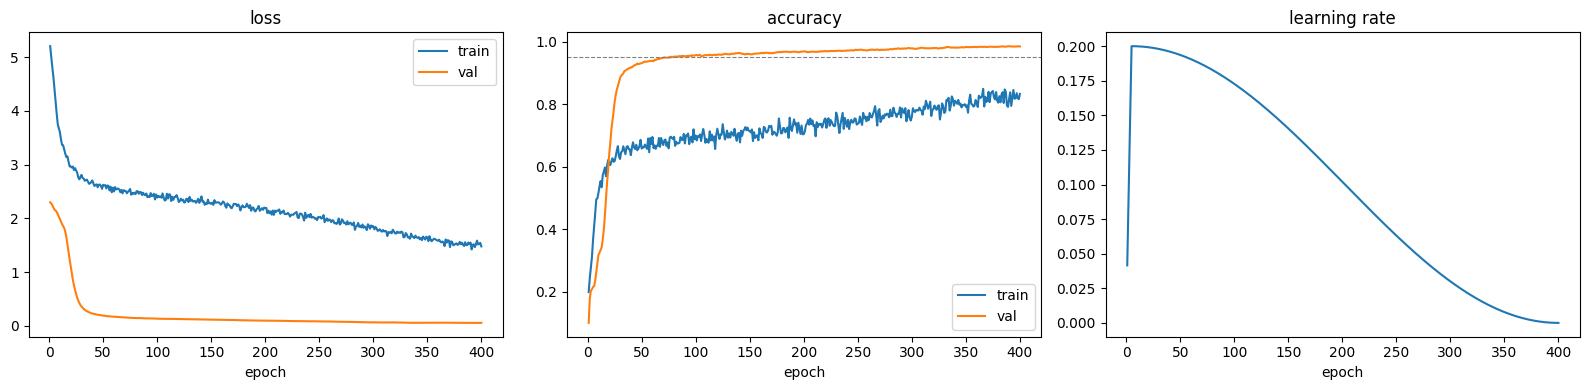

In [15]:
h = pd.DataFrame(state["history"])
if len(h):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="val"); ax[1].set_title("accuracy"); ax[1].legend()
    ax[1].axhline(0.95, ls="--", c="grey", lw=0.8)
    ax[2].plot(h.epoch, h.lr); ax[2].set_title("learning rate")
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "curves.png"), dpi=120); plt.show()

## 12. Evaluate best.pt: accuracy and per-class diagnostics on validation and internal test

best.pt: epoch 390, val acc 0.9856, params 4,998,738 (EMA weights: True)
SLA inference on VAL: sd 0.9852 | ag 0.9828 | sdag 0.9836 -> using 'sd'

=== VALIDATION (n=2500) ===
accuracy 0.9852 | macro recall 0.9852 (equal to accuracy on a balanced split) | min class cat 0.968 | weakest-3 mean 0.9720 | recall std 0.0100, range 0.028 | errors 37
            recall  errors  mean p(true)  mean NLL
airplane     0.980       5        0.9705    0.0471
automobile   0.984       4        0.9728    0.0569
bird         0.988       3        0.9749    0.0362
cat          0.968       8        0.9440    0.0900
deer         0.996       1        0.9766    0.0283
dog          0.968       8        0.9334    0.1232
frog         0.996       1        0.9842    0.0192
horse        0.988       3        0.9728    0.0482
ship         0.996       1        0.9761    0.0335
truck        0.988       3        0.9758    0.0603
top confusions (count, true -> predicted): 4 dog->cat, 4 cat->dog, 2 dog->deer, 2 automobile->tr

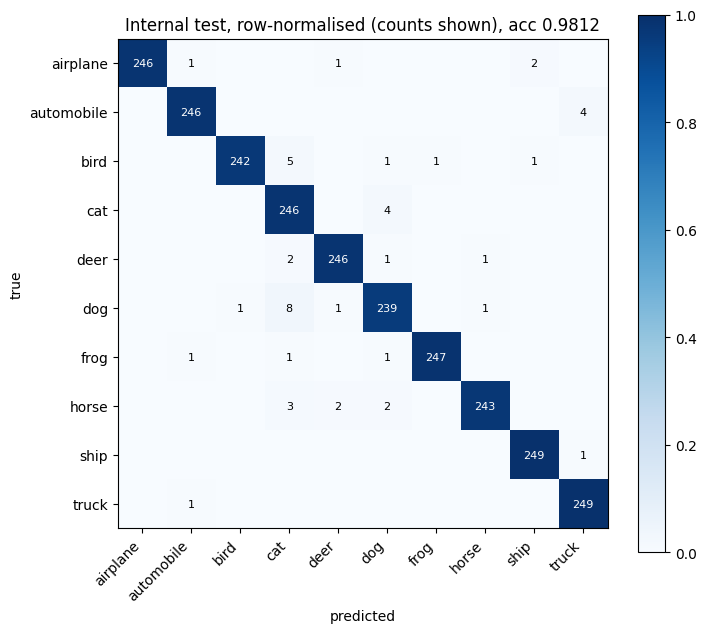


saved results.json and confusion_internal_test.png in /content/drive/MyDrive/cifar10_resnet_challenge/runs/kd_sewrn_only_student_resnext29_slasd_400ep_v1

student internal test 0.9812 | teacher ensemble 0.9840 | best single teacher 0.9840


In [16]:
# ---- 12. Evaluate best.pt: overall + per-class diagnostics on VAL and INTERNAL TEST ----
best = torch.load(BEST_CKPT, map_location=device, weights_only=False)
eval_model = build_model(best["cfg"]).to(device).to(memory_format=torch.channels_last)
eval_model.load_state_dict(best["model"]); eval_model.eval()
assert not eval_model.training
print(f"best.pt: epoch {best['epoch']}, val acc {best['val_acc']:.4f}, params {count_params(eval_model):,} "
      f"(EMA weights: {best.get('is_ema', False)})")

def class_report(probs, y, split_name):
    """Overall accuracy plus per-class recall, worst-class stats, confusions and confidence."""
    pred = probs.argmax(1)
    p = probs / probs.sum(1, keepdim=True)                       # TTA sums -> probabilities
    cm = torch.bincount(y * 10 + pred, minlength=100).view(10, 10).cpu()
    recall = (cm.diag().float() / cm.sum(1).float()).numpy()
    true_conf = p[torch.arange(len(y), device=y.device), y].cpu().numpy()
    nll = -np.log(np.clip(true_conf, 1e-12, None))
    yc = y.cpu().numpy()
    per_class = pd.DataFrame({
        "recall": recall,
        "errors": (cm.sum(1) - cm.diag()).numpy(),
        "mean p(true)": [true_conf[yc == c].mean() for c in range(10)],
        "mean NLL": [nll[yc == c].mean() for c in range(10)],
    }, index=CLASS_NAMES)
    off = cm.clone(); off.fill_diagonal_(0)
    top = sorted(((int(off[i, j]), CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if off[i, j] > 0), reverse=True)[:8]
    srt = np.sort(recall)
    summary = {
        "split": split_name, "n": int(len(y)),
        "accuracy": float((pred == y).float().mean()),
        "macro_recall": float(recall.mean()),
        "min_class_recall": float(srt[0]), "min_class": CLASS_NAMES[int(np.argmin(recall))],
        "mean_recall_weakest3": float(srt[:3].mean()),
        "recall_std": float(recall.std()), "recall_range": float(srt[-1] - srt[0]),
        "errors": int((pred != y).sum()),
    }
    print(f"\n=== {split_name} (n={len(y)}) ===")
    print(f"accuracy {summary['accuracy']:.4f} | macro recall {summary['macro_recall']:.4f} (equal to accuracy on a balanced split)"
          f" | min class {summary['min_class']} {summary['min_class_recall']:.3f} | weakest-3 mean {summary['mean_recall_weakest3']:.4f}"
          f" | recall std {summary['recall_std']:.4f}, range {summary['recall_range']:.3f} | errors {summary['errors']}")
    print(per_class.round(4).to_string())
    print("top confusions (count, true -> predicted):", ", ".join(f"{n} {a}->{b}" for n, a, b in top))
    return summary, cm, per_class

if getattr(eval_model, "fc_joint", None) is not None:
    # SLA model: choose the inference mode on VALIDATION only; anything other than SD must win by 0.2 pt (5 images)
    accs = {md: (predict_logits(eval_model, Xva, tta=CFG["TTA_FLIP"], mode=md).argmax(1) == yva).float().mean().item()
            for md in ("sd", "ag", "sdag")}
    alt = max(("ag", "sdag"), key=lambda md: accs[md])
    INFER_MODE = alt if accs[alt] > accs["sd"] + 0.002 else "sd"
    print("SLA inference on VAL: " + " | ".join(f"{md} {v:.4f}" for md, v in accs.items()) + f" -> using '{INFER_MODE}'")
val_probs_best = predict_logits(eval_model, Xva, tta=CFG["TTA_FLIP"])
test_probs_best = predict_logits(eval_model, Xte_int, tta=CFG["TTA_FLIP"])
val_sum, val_cm, _ = class_report(val_probs_best, yva, "VALIDATION")
test_sum, test_cm, test_pc = class_report(test_probs_best, yte_int, "INTERNAL TEST")
test_acc = test_sum["accuracy"]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
cmn = test_cm.float() / test_cm.sum(1, keepdim=True).float()
im = ax.imshow(cmn.numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        if test_cm[i, j] > 0:
            ax.text(j, i, int(test_cm[i, j]), ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Internal test, row-normalised (counts shown), acc {test_acc:.4f}")
plt.colorbar(im); plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "confusion_internal_test.png"), dpi=120); plt.show()

with open(os.path.join(RUN_DIR, "results.json"), "w") as f:
    json.dump({"run": CFG["RUN_NAME"], "best_epoch": best["epoch"], "n_params": N_PARAMS,
               "val": val_sum, "internal_test": test_sum,
               "internal_test_per_class": test_pc.round(4).to_dict()}, f, indent=1)
print("\nsaved results.json and confusion_internal_test.png in", RUN_DIR)
if CFG.get("KD_ALPHA", 0) > 0 and "ens_test_acc" in globals():
    print(f"\nstudent internal test {test_acc:.4f} | teacher ensemble {ens_test_acc:.4f} | best single teacher {best_single_test:.4f}")


## 13. Kaggle submission

In [17]:
# ---- 13. Kaggle submission from ONE network (best.pt), with strict checks ----
assert not eval_model.training, "model must be in eval mode"
kp = predict_logits(eval_model, Xkaggle, tta=CFG["TTA_FLIP"]).argmax(1).cpu().numpy()
sub = pd.DataFrame({"id": test_ids.astype(int), "label": kp.astype(int)})

assert list(sub.columns) == ["id", "label"], "schema must be exactly id,label"
assert len(sub) == len(SAMPLE_SUB) == len(Xkaggle), "one prediction per evaluation image"
assert (sub["id"].values == SAMPLE_SUB["id"].values).all(), "ids/order must match sample_submission"
assert sub["id"].is_unique and not sub.isna().any().any(), "no duplicate or missing values"
assert sub["label"].between(0, 9).all() and pd.api.types.is_integer_dtype(sub["label"]), "labels must be integers 0-9"

stamp = time.strftime("%Y%m%d_%H%M")
drive_sub = os.path.join(RUN_DIR, f"submission_{stamp}_val{best['val_acc']:.4f}_test{test_acc:.4f}.csv")
sub.to_csv(drive_sub, index=False)
local_sub = os.path.join(WORK_DIR, "submission.csv"); sub.to_csv(local_sub, index=False)
chk = pd.read_csv(local_sub)
assert chk.equals(sub), "re-read check failed"
print("saved:", drive_sub, "\nand:", local_sub)
print("predicted class counts:", dict(zip(CLASS_NAMES, np.bincount(kp, minlength=10).tolist())))

# how different is this from earlier submissions? (tells you how big a public-score change must be to be real)
prev = sorted(glob.glob(os.path.join(DRIVE_ROOT, "runs", "*", "submission_*.csv")))
prev = [p for p in prev if os.path.dirname(p) != RUN_DIR]
for p in prev[-6:]:
    d = (pd.read_csv(p)["label"].values != kp).mean()
    print(f"  differs from {os.path.relpath(p, DRIVE_ROOT)[:70]:70s} on {d:5.1%} -> public change < ~{2*math.sqrt(max(d,1e-9)/1000):.3f} is noise")

saved: /content/drive/MyDrive/cifar10_resnet_challenge/runs/kd_sewrn_only_student_resnext29_slasd_400ep_v1/submission_20261104_0115_val0.9856_test0.9812.csv 
and: /content/work/submission.csv
predicted class counts: {'airplane': 180, 'automobile': 217, 'bird': 213, 'cat': 211, 'deer': 196, 'dog': 206, 'frog': 182, 'horse': 199, 'ship': 202, 'truck': 194}
  differs from runs/resnet_w64-128-256_b333_ta_v1/submission_20261030_0450_val0.9672_ on  8.8% -> public change < ~0.019 is noise
  differs from runs/resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1/submission_20261030_ on  7.0% -> public change < ~0.017 is noise
  differs from runs/resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1/submission_tta_noTTA on  7.1% -> public change < ~0.017 is noise
  differs from runs/resnext29_4x24d_ta_ema_cutmix_sam_v1/submission_20261031_0022_val on  6.8% -> public change < ~0.016 is noise
  differs from runs/resnext29_4x24d_w280-544-1040_costpen_v1/submission_20261031_0508 on  7.5% -> public change < ~0.017 is

In [18]:
if IN_COLAB:
    from google.colab import files
    files.download(local_sub)   # the file must be named submission.csv when uploaded to Kaggle

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>